In [34]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [35]:
tf.random.set_seed(42)
np.random.seed(42)

In [36]:
dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"

dataset_path = tf.keras.utils.get_file(
    fname="flower_photos.tgz",
    origin=dataset_url,
    extract=True
)

In [37]:
expected_classes = {"daisy", "dandelion", "roses", "sunflowers", "tulips"}

In [38]:
search_roots = [
    Path.home() / ".keras" / "datasets",
    Path(dataset_path).parent,
    Path.cwd()
]

data_dir = None

for root in search_roots:
    if root.exists():
        candidates = [root] + list(root.rglob("flower_photos"))

        for candidate in candidates:
            if candidate.is_dir():
                folders = {
                    p.name for p in candidate.iterdir() if p.is_dir()
                }

                if expected_classes.issubset(folders):
                    data_dir = candidate
                    break

    if data_dir is not None:
        break

if data_dir is None:
    raise FileNotFoundError(
        "Flower dataset folder not found. Check the download and extraction."
    )

print("Dataset path:", data_dir)

Dataset path: /root/.keras/datasets/flower_photos_extracted/flower_photos


In [39]:
IMG_SIZE = (180, 180)
BATCH_SIZE = 32
SEED = 42

In [40]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)


Found 3670 files belonging to 5 classes.
Using 2936 files for training.


In [41]:
val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

Found 3670 files belonging to 5 classes.
Using 734 files for validation.


In [42]:
class_names = train_ds.class_names
NUM_CLASSES = len(class_names)

print("\nFlower Categories:", class_names)
print("Number of Classes:", NUM_CLASSES)


Flower Categories: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
Number of Classes: 5


In [43]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

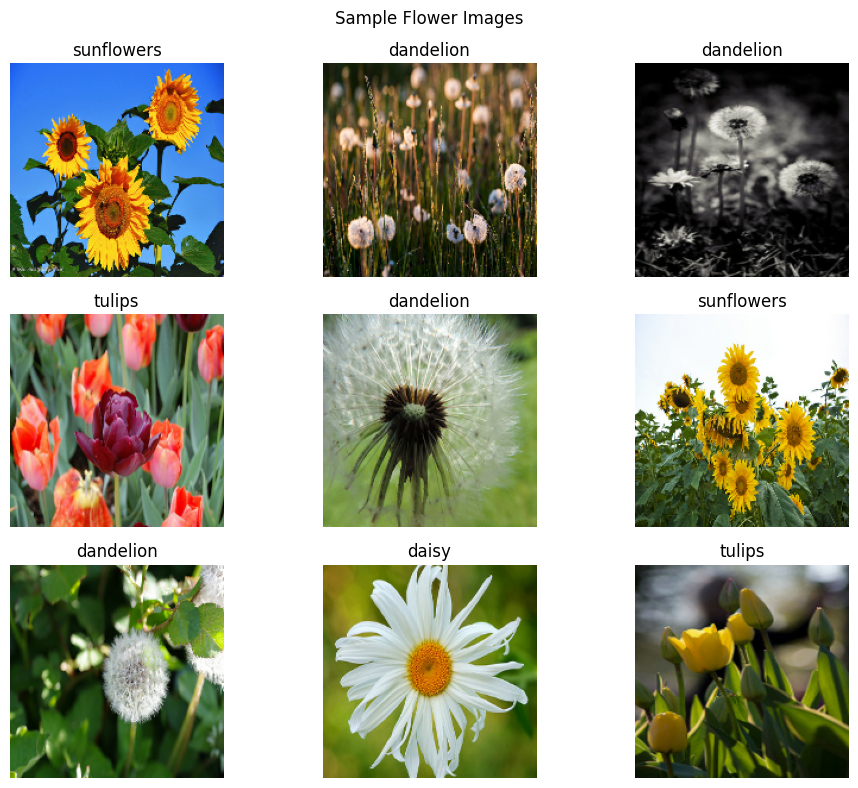

In [44]:
plt.figure(figsize=(10, 8))

for images, labels in train_ds.take(1):

    for i in range(min(9, len(images))):

        plt.subplot(3, 3, i + 1)
        plt.imshow(tf.cast(images[i], tf.uint8))
        plt.title(class_names[int(labels[i])])
        plt.axis('off')

plt.suptitle("Sample Flower Images")
plt.tight_layout()
plt.show()

In [45]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(180, 180, 3)),
    tf.keras.layers.Rescaling(1.0 / 255),

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")
])

model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │     6,553,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,647,621 (25.36 MB)

 Trainable params: 6,647,621 (25.36 MB)

 Non-trainable params: 0 (0.00 B)

In [46]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

In [47]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)


In [57]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stopping]
)

Epoch 1/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 231s 2s/step - accuracy: 0.6754 - loss: 0.8342 - val_accuracy: 0.6812 - val_loss: 0.8557
Epoch 2/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 234s 3s/step - accuracy: 0.7231 - loss: 0.7217 - val_accuracy: 0.6839 - val_loss: 0.8569
Epoch 3/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 260s 3s/step - accuracy: 0.7663 - loss: 0.6495 - val_accuracy: 0.6853 - val_loss: 0.8842
Epoch 4/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 261s 3s/step - accuracy: 0.7922 - loss: 0.5365 - val_accuracy: 0.6812 - val_loss: 1.0068


In [ ]:
val_loss, val_accuracy = model.evaluate(val_ds, verbose=0)

print(f"Validation loss: {val_loss:.4f}")
print(f"Validation accuracy: {val_accuracy * 100:.2f}%")

In [ ]:
# Collect actual labels and predicted labels
y_true = []
y_pred = []

for images, labels in val_ds:

    predictions = model.predict(images, verbose=0)
    predicted_labels = np.argmax(predictions, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_labels)

In [ ]:
print("\n========== CLASSIFICATION REPORT ==========")

print(classification_report(
        y_true,
        y_pred,
        labels=list(range(NUM_CLASSES)),
        target_names=class_names,
        digits=4,
        zero_division=0))

In [ ]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names)

disp.plot(cmap="Blues", xticks_rotation=45)

plt.title("CNN Flower Classification - Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(12, 10))

for images, labels in val_ds.take(1):
    probabilities = model.predict(images, verbose=0)

    for i in range(min(9, len(images))):
        predicted_idx = int(np.argmax(probabilities[i]))
        actual_idx = int(labels[i].numpy())
        confidence = float(probabilities[i][predicted_idx]) * 100

        plt.subplot(3, 3, i + 1)
        plt.imshow(tf.cast(images[i], tf.uint8).numpy())
        plt.title(
            f"Actual: {class_names[actual_idx]}\n"
            f"Predicted: {class_names[predicted_idx]}\n"
            f"Confidence: {confidence:.1f}%"
        )
        plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], marker="o", label="Training accuracy")
plt.plot(history.history["val_accuracy"], marker="o", label="Validation accuracy")

plt.title("Training vs Validation Accuracy Curve")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
model.save("flower_classification_cnn.keras")